# decision tree
Decision Tree with depth=3 on cleaned composite data.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

### Load clean dataset

In [3]:
df = pd.read_csv('mental_health_clean.csv')
print("Shape:", df.shape)
df.head()

Shape: (10000, 5)


,Overall_Risk_Index,Total_Distress_Score,Severe_Risk_Score,Social_Support,Has_Mental_Health_Issue
0,63,53,2,9,1
1,71,71,0,3,1
2,84,74,2,5,1
3,51,41,2,1,1
4,78,78,0,1,1


### Train test split

In [4]:
X = df.drop('Has_Mental_Health_Issue', axis=1)
y = df['Has_Mental_Health_Issue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (8000, 4)
Test shape : (2000, 4)


### Train Decision Tree

In [5]:
model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=10,
    class_weight={0: 8, 1: 1},
    random_state=42
)

model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

### Check accuracy

In [6]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Train accuracy:", round(accuracy_score(y_train, y_train_pred) * 100, 2), "%")
print("Test accuracy :", round(accuracy_score(y_test, y_test_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Train accuracy: 79.29 %
Test accuracy : 78.15 %

Classification Report:
              precision    recall  f1-score   support

           0       0.16      0.43      0.23       157
           1       0.94      0.81      0.87      1843

    accuracy                           0.78      2000
   macro avg       0.55      0.62      0.55      2000
weighted avg       0.88      0.78      0.82      2000



### Confusion matrix

Confusion Matrix:
[[  67   90]
 [ 347 1496]]


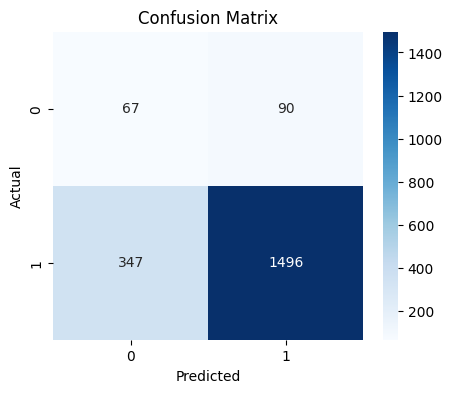

In [7]:
cm = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Decision tree plot

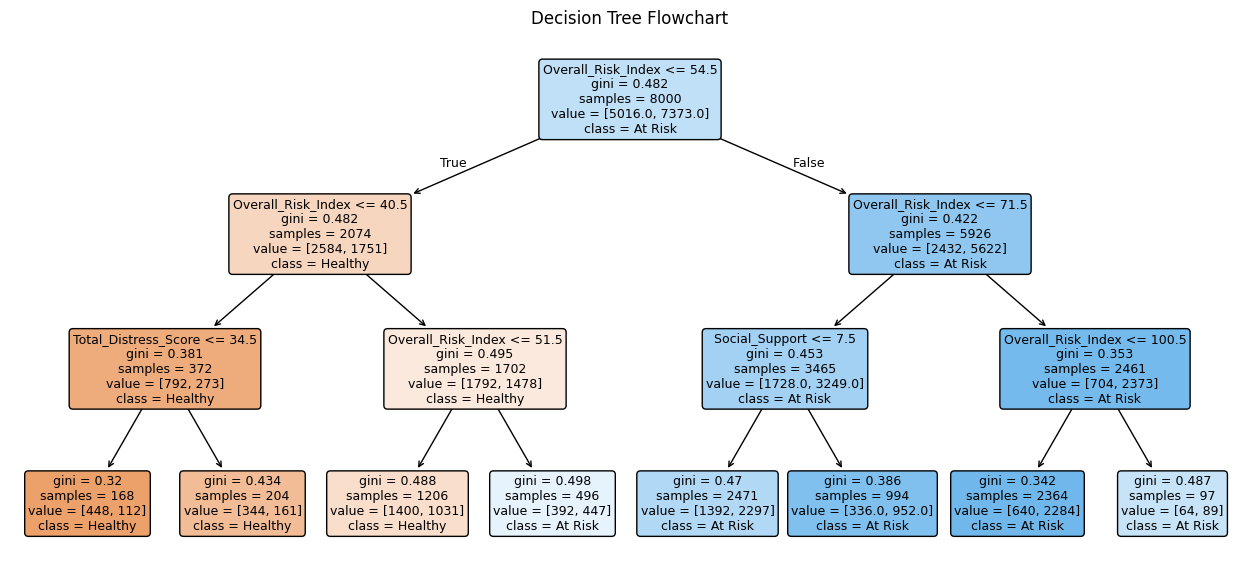

In [8]:
plt.figure(figsize=(16, 7))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Healthy', 'At Risk'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Decision Tree Flowchart')
plt.savefig('decision_tree_flowchart.png', bbox_inches='tight')
plt.show()

### Save model

In [9]:
joblib.dump(model, 'decision_tree_model.pkl')
print("Model saved as decision_tree_model.pkl")

Model saved as decision_tree_model.pkl
